In [39]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("CART TO DOOR - Rashi's Project")
print("Python Version:", sys.version)
print("Pandas Version:", pd.__version__)
print("All libraries imported successfully!")

CART TO DOOR - Rashi's Project
Python Version: 3.14.10 (tags/v3.14.10:b703b2c, Oct 25 2026, 17:36:52) [MSC v.1944 64 bit (AMD64)]
Pandas Version: 3.1.1
All libraries imported successfully!


In [40]:
from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("CartToDoor_Rashi") \
    .master("local[*]") \
    .config("spark.driver.memory", "4g") \
    .getOrCreate()

print("Spark successfully started!")
print("Spark Version:", spark.version)

Spark successfully started!
Spark Version: 4.3.0


In [41]:
import os

DATA_PATH = "../data/raw/archive"

print("Checking dataset folder...")

if os.path.exists(DATA_PATH):
    print("Dataset folder found!")
    print("\nAvailable CSV files:")
    for file in os.listdir(DATA_PATH):
        if file.endswith(".csv"):
            print(file)
else:
    print("Dataset folder NOT found. Please check the path.")

Checking dataset folder...
Dataset folder found!

Available CSV files:
olist_customers_dataset.csv
olist_geolocation_dataset.csv
olist_orders_dataset.csv
olist_order_items_dataset.csv
olist_order_payments_dataset.csv
olist_order_reviews_dataset.csv
olist_products_dataset.csv
olist_sellers_dataset.csv
product_category_name_translation.csv


In [42]:
# Loading all Olist datasets using Apache Spark

files = {
    "customers": "olist_customers_dataset.csv",
    "geolocation": "olist_geolocation_dataset.csv",
    "order_items": "olist_order_items_dataset.csv",
    "payments": "olist_order_payments_dataset.csv",
    "reviews": "olist_order_reviews_dataset.csv",
    "orders": "olist_orders_dataset.csv",
    "products": "olist_products_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "category_translation": "product_category_name_translation.csv"
}

datasets = {}

for name, filename in files.items():
    file_path = os.path.join(DATA_PATH, filename)

    datasets[name] = (
        spark.read
        .option("header", "true")
        .option("inferSchema", "true")
        .option("multiLine", "true")
        .csv(file_path)
    )

    print(f"{name} dataset loaded successfully!")

print("\nTOTAL DATASETS LOADED:", len(datasets))

customers dataset loaded successfully!
geolocation dataset loaded successfully!
order_items dataset loaded successfully!
payments dataset loaded successfully!
reviews dataset loaded successfully!
orders dataset loaded successfully!
products dataset loaded successfully!
sellers dataset loaded successfully!
category_translation dataset loaded successfully!

TOTAL DATASETS LOADED: 9


In [43]:
# CART TO DOOR - Dataset Overview

print("========== DATASET OVERVIEW ==========\n")

for name, df in datasets.items():
    print(f"\nDataset Name: {name.upper()}")
    print("Total Rows:", df.count())
    print("Total Columns:", len(df.columns))
    print("Column Names:", df.columns)

print("\n========== OVERVIEW COMPLETED ==========")

========== DATASET OVERVIEW ==========


Dataset Name: CUSTOMERS


Total Rows: 99441
Total Columns: 5
Column Names: ['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']

Dataset Name: GEOLOCATION
Total Rows: 1000163
Total Columns: 5
Column Names: ['geolocation_zip_code_prefix', 'geolocation_lat', 'geolocation_lng', 'geolocation_city', 'geolocation_state']

Dataset Name: ORDER_ITEMS
Total Rows: 112650
Total Columns: 7
Column Names: ['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']

Dataset Name: PAYMENTS
Total Rows: 103886
Total Columns: 5
Column Names: ['order_id', 'payment_sequential', 'payment_type', 'payment_installments', 'payment_value']

Dataset Name: REVIEWS
Total Rows: 99249
Total Columns: 7
Column Names: ['review_id', 'order_id', 'review_score', 'review_comment_title', 'review_comment_message', 'review_creation_date', 'review_answer_timestamp']

Dataset Name: ORDERS
Total Rows: 99450
Total Columns: 8
Column Names: ['order_id', 'customer_id'

In [44]:
# Dataset Summary Table

summary = []

for name, df in datasets.items():
    summary.append({
        "Dataset": name,
        "Total Rows": df.count(),
        "Total Columns": len(df.columns)
    })

summary_df = pd.DataFrame(summary)

display(summary_df)

print("Total Datasets:", len(summary_df))
print("Total Records:", summary_df["Total Rows"].sum())

,Dataset,Total Rows,Total Columns
0,customers,99441,5
1,geolocation,1000163,5
2,order_items,112650,7
3,payments,103886,5
4,reviews,99249,7
5,orders,99450,8
6,products,32951,9
7,sellers,3095,4
8,category_translation,71,2


Total Datasets: 9
Total Records: 1550956


In [45]:
from pyspark.sql.functions import col, sum, when, trim

orders_df = datasets["orders"]

missing_values = orders_df.select([
    sum(
        when(
            col(c).isNull() | (trim(col(c).cast("string")) == ""),
            1
        ).otherwise(0)
    ).alias(c)
    for c in orders_df.columns
])

print("MISSING VALUES IN ORDERS DATASET")
missing_values.show(truncate=False)

MISSING VALUES IN ORDERS DATASET
+--------+-----------+------------+------------------------+-----------------+----------------------------+-----------------------------+-----------------------------+
|order_id|customer_id|order_status|order_purchase_timestamp|order_approved_at|order_delivered_carrier_date|order_delivered_customer_date|order_estimated_delivery_date|
+--------+-----------+------------+------------------------+-----------------+----------------------------+-----------------------------+-----------------------------+
|9       |9          |9           |9                       |169              |1792                        |2974                         |9                            |
+--------+-----------+------------+------------------------+-----------------+----------------------------+-----------------------------+-----------------------------+



In [46]:
# Duplicate Records Analysis - Orders Dataset

orders_df = datasets["orders"]

total_records = orders_df.count()
unique_orders = orders_df.select("order_id").distinct().count()
duplicate_orders = total_records - unique_orders

print("========== DUPLICATE ANALYSIS ==========")
print("Total Order Records:", total_records)
print("Unique Order IDs:", unique_orders)
print("Duplicate Order IDs:", duplicate_orders)
print("========================================")

========== DUPLICATE ANALYSIS ==========
Total Order Records: 99450
Unique Order IDs: 99442
Duplicate Order IDs: 8


In [47]:
# Order Status Analysis

from pyspark.sql.functions import count

orders_df = datasets["orders"]

status_analysis = (
    orders_df
    .groupBy("order_status")
    .agg(count("order_id").alias("total_orders"))
    .orderBy("total_orders", ascending=False)
)

print("========== ORDER STATUS ANALYSIS ==========")
status_analysis.show(truncate=False)

========== ORDER STATUS ANALYSIS ==========
+------------+------------+
|order_status|total_orders|
+------------+------------+
|delivered   |96478       |
|shipped     |1107        |
|canceled    |625         |
|unavailable |609         |
|invoiced    |314         |
|processing  |301         |
|created     |5           |
|approved    |2           |
|NULL        |0           |
+------------+------------+



In [48]:
from pyspark.sql.functions import col, date_format, count, try_to_timestamp, lit

orders_df = datasets["orders"]

monthly_orders = (
    orders_df
    .withColumn(
        "purchase_date",
        try_to_timestamp(
            col("order_purchase_timestamp"),
            lit("yyyy-MM-dd HH:mm:ss")
        )
    )
    .withColumn(
        "month",
        date_format(col("purchase_date"), "yyyy-MM")
    )
    .filter(col("month").isNotNull())
    .groupBy("month")
    .agg(count("order_id").alias("total_orders"))
    .orderBy("month")
)

print("========== MONTHLY ORDER TREND ==========")
monthly_orders.show(30, truncate=False)

========== MONTHLY ORDER TREND ==========
+-----+------------+
|month|total_orders|
+-----+------------+
+-----+------------+



c:\Users\HP\Desktop\Cart_to_Door\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
c:\Users\HP\Desktop\Cart_to_Door\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:374: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


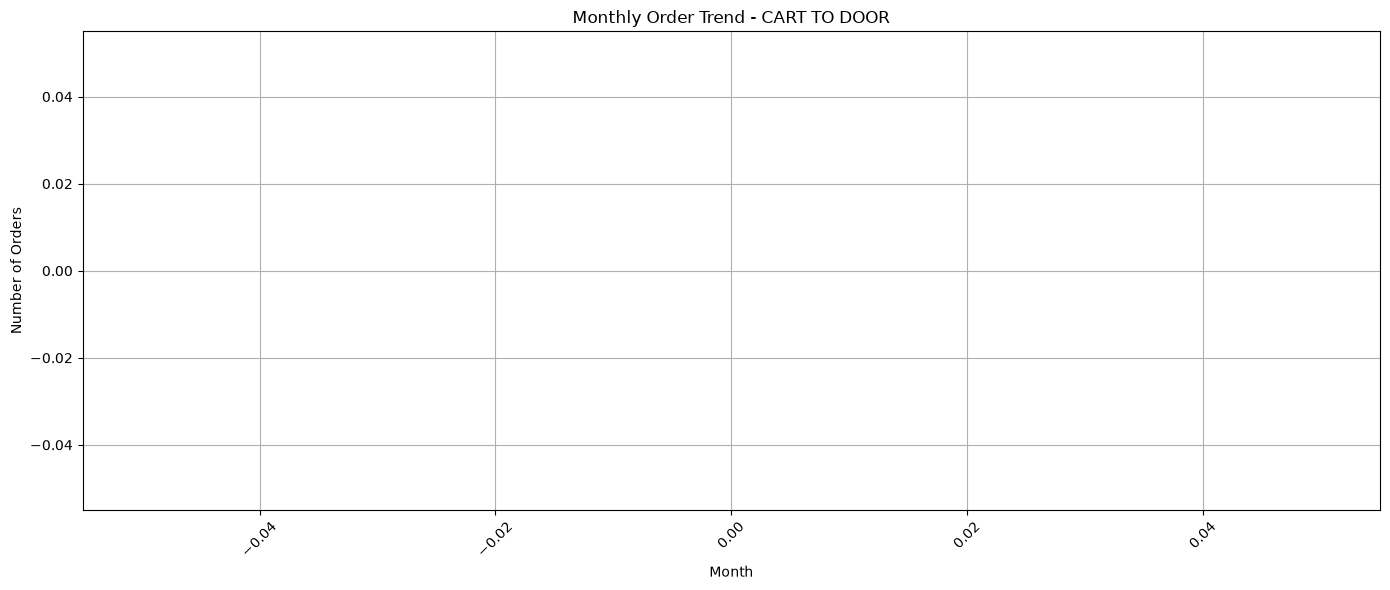

In [49]:
# Monthly Order Trend Visualization

monthly_pd = monthly_orders.toPandas()

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_pd["month"],
    monthly_pd["total_orders"],
    marker="o",
    linewidth=2
)

plt.title("Monthly Order Trend - CART TO DOOR")
plt.xlabel("Month")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.show()

In [50]:
print("Monthly data shape:", monthly_pd.shape)

print("\nMonthly data:")
display(monthly_pd)

print("\nNumber of months:", len(monthly_pd))

Monthly data shape: (0, 2)

Monthly data:


,month,total_orders



Number of months: 0


In [51]:
# Checking original order date values

orders_df = datasets["orders"]

print("DATE COLUMN DATA TYPE:")
orders_df.select("order_purchase_timestamp").printSchema()

print("\nFIRST 10 ORIGINAL DATE VALUES:")
orders_df.select("order_purchase_timestamp").show(10, truncate=False)

DATE COLUMN DATA TYPE:
root
 |-- order_purchase_timestamp: string (nullable = true)


FIRST 10 ORIGINAL DATE VALUES:
+------------------------+
|order_purchase_timestamp|
+------------------------+
|10/2/2017 10:56         |
|7/24/2018 20:41         |
|8/8/2018 8:38           |
|11/18/2017 19:28        |
|2/13/2018 21:18         |
|7/9/2017 21:57          |
|4/11/2017 12:22         |
|5/16/2017 13:10         |
|1/23/2017 18:29         |
|7/29/2017 11:55         |
+------------------------+
only showing top 10 rows


In [52]:
from pyspark.sql.functions import to_timestamp, date_format, col, count

orders_df = datasets["orders"]

monthly_orders = (
    orders_df
    .withColumn(
        "purchase_date",
        to_timestamp(
            col("order_purchase_timestamp"),
            "M/d/yyyy H:mm"
        )
    )
    .withColumn(
        "month",
        date_format(col("purchase_date"), "yyyy-MM")
    )
    .filter(col("month").isNotNull())
    .groupBy("month")
    .agg(count("order_id").alias("total_orders"))
    .orderBy("month")
)

print("MONTHLY ORDER TREND")
monthly_orders.show(30, truncate=False)

print("Total Months:", monthly_orders.count())

MONTHLY ORDER TREND
+-------+------------+
|month  |total_orders|
+-------+------------+
|2016-09|4           |
|2016-10|324         |
|2016-12|1           |
|2017-01|800         |
|2017-02|1780        |
|2017-03|2682        |
|2017-04|2404        |
|2017-05|3700        |
|2017-06|3245        |
|2017-07|4026        |
|2017-08|4331        |
|2017-09|4285        |
|2017-10|4631        |
|2017-11|7544        |
|2017-12|5673        |
|2018-01|7269        |
|2018-02|6728        |
|2018-03|7211        |
|2018-04|6939        |
|2018-05|6873        |
|2018-06|6167        |
|2018-07|6292        |
|2018-08|6512        |
|2018-09|16          |
|2018-10|4           |
+-------+------------+

Total Months: 25


c:\Users\HP\Desktop\Cart_to_Door\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
c:\Users\HP\Desktop\Cart_to_Door\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:374: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


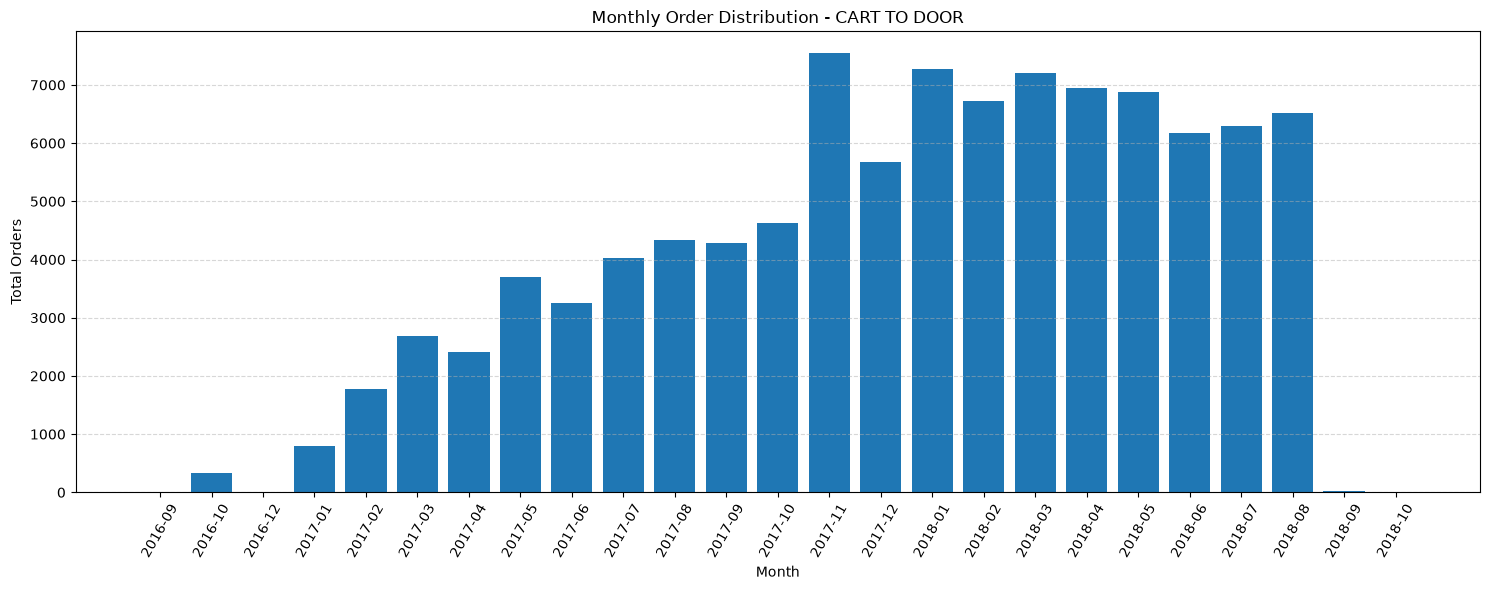

In [53]:
monthly_pd = monthly_orders.toPandas()

plt.figure(figsize=(15, 6))

plt.bar(
    monthly_pd["month"],
    monthly_pd["total_orders"]
)

plt.title("Monthly Order Distribution - CART TO DOOR")
plt.xlabel("Month")
plt.ylabel("Total Orders")
plt.xticks(rotation=60)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()

plt.show()

In [54]:
# Customer Analysis

customers_df = datasets["customers"]

total_customer_records = customers_df.count()

unique_customers = (
    customers_df
    .select("customer_unique_id")
    .distinct()
    .count()
)

unique_customer_locations = (
    customers_df
    .select("customer_city")
    .distinct()
    .count()
)

print("========== CUSTOMER ANALYSIS ==========")
print("Total Customer Records:", total_customer_records)
print("Unique Customers:", unique_customers)
print("Unique Customer Cities:", unique_customer_locations)
print("=======================================")

========== CUSTOMER ANALYSIS ==========
Total Customer Records: 99441
Unique Customers: 96096
Unique Customer Cities: 4119


In [55]:
# Top 10 Cities by Customer Records

from pyspark.sql.functions import count

city_analysis = (
    customers_df
    .groupBy("customer_city")
    .agg(count("customer_id").alias("total_customers"))
    .orderBy("total_customers", ascending=False)
)

print("TOP 10 CUSTOMER CITIES")
city_analysis.show(10, truncate=False)

TOP 10 CUSTOMER CITIES
+---------------------+---------------+
|customer_city        |total_customers|
+---------------------+---------------+
|sao paulo            |15540          |
|rio de janeiro       |6882           |
|belo horizonte       |2773           |
|brasilia             |2131           |
|curitiba             |1521           |
|campinas             |1444           |
|porto alegre         |1379           |
|salvador             |1245           |
|guarulhos            |1189           |
|sao bernardo do campo|938            |
+---------------------+---------------+
only showing top 10 rows


c:\Users\HP\Desktop\Cart_to_Door\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
c:\Users\HP\Desktop\Cart_to_Door\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:374: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


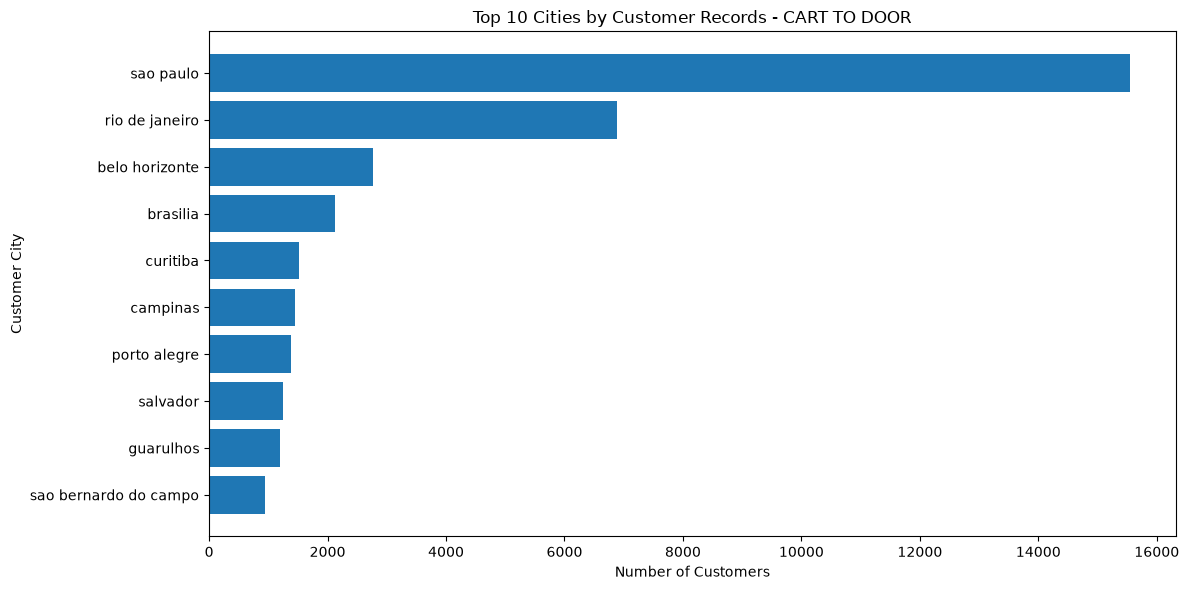

In [56]:
# Top 10 Customer Cities Visualization

city_pd = city_analysis.limit(10).toPandas()

plt.figure(figsize=(12, 6))

plt.barh(
    city_pd["customer_city"][::-1],
    city_pd["total_customers"][::-1]
)

plt.title("Top 10 Cities by Customer Records - CART TO DOOR")
plt.xlabel("Number of Customers")
plt.ylabel("Customer City")
plt.tight_layout()

plt.show()

In [57]:
# Delivered vs Other Orders Analysis

from pyspark.sql.functions import when, sum as spark_sum

delivery_summary = (
    orders_df
    .withColumn(
        "delivery_category",
        when(col("order_status") == "delivered", "Delivered")
        .otherwise("Other Orders")
    )
    .groupBy("delivery_category")
    .count()
)

delivery_summary.show()

+-----------------+-----+
|delivery_category|count|
+-----------------+-----+
|     Other Orders| 2972|
|        Delivered|96478|
+-----------------+-----+



In [58]:
# Delivery Status Percentage Analysis

from pyspark.sql.functions import round

total_orders = orders_df.count()

delivery_percentage = (
    orders_df
    .withColumn(
        "delivery_category",
        when(col("order_status") == "delivered", "Delivered")
        .otherwise("Other Orders")
    )
    .groupBy("delivery_category")
    .count()
    .withColumn(
        "percentage",
        round((col("count") / total_orders) * 100, 2)
    )
    .orderBy("percentage", ascending=False)
)

print("========== DELIVERY PERFORMANCE ==========")
delivery_percentage.show(truncate=False)

========== DELIVERY PERFORMANCE ==========
+-----------------+-----+----------+
|delivery_category|count|percentage|
+-----------------+-----+----------+
|Delivered        |96478|97.01     |
|Other Orders     |2972 |2.99      |
+-----------------+-----+----------+



c:\Users\HP\Desktop\Cart_to_Door\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
c:\Users\HP\Desktop\Cart_to_Door\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:374: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


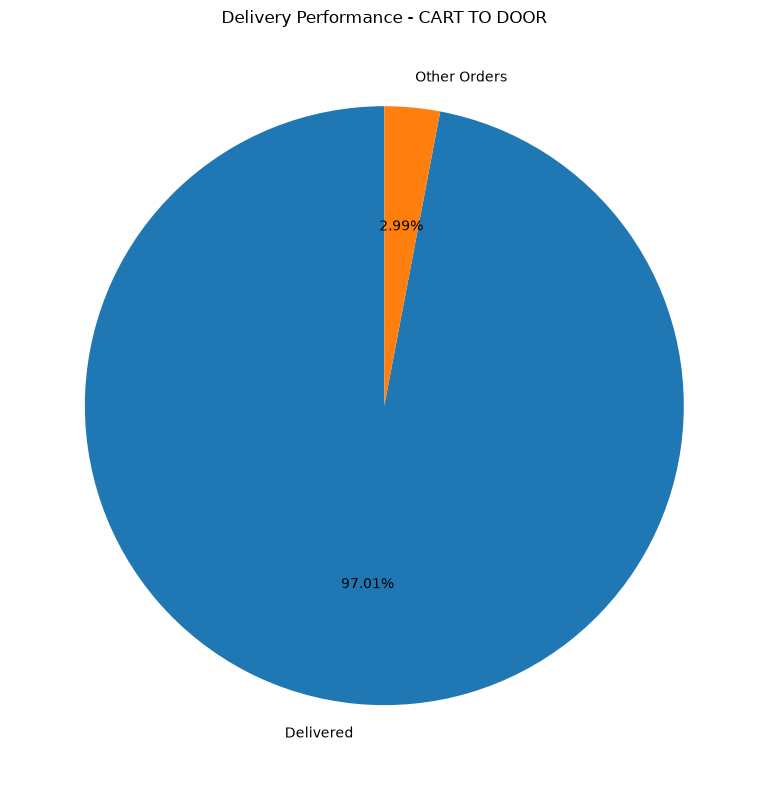

In [59]:
# Delivery Performance Pie Chart

delivery_pd = delivery_percentage.toPandas()

plt.figure(figsize=(8, 8))

plt.pie(
    delivery_pd["count"],
    labels=delivery_pd["delivery_category"],
    autopct="%1.2f%%",
    startangle=90
)

plt.title("Delivery Performance - CART TO DOOR")
plt.tight_layout()
plt.show()

In [60]:
# Delivery Time Analysis

from pyspark.sql.functions import datediff, avg, min, max, round, col, to_timestamp

delivery_df = orders_df.withColumn(
    "purchase_date",
    to_timestamp(col("order_purchase_timestamp"), "M/d/yyyy H:mm")
).withColumn(
    "delivered_date",
    to_timestamp(col("order_delivered_customer_date"), "M/d/yyyy H:mm")
)

delivery_time = (
    delivery_df
    .filter(
        (col("order_status") == "delivered") &
        col("purchase_date").isNotNull() &
        col("delivered_date").isNotNull()
    )
    .withColumn(
        "delivery_days",
        (col("delivered_date").cast("long") -
         col("purchase_date").cast("long")) / 86400
    )
)

delivery_time.select(
    round(avg("delivery_days"), 2).alias("Average Delivery Days"),
    round(min("delivery_days"), 2).alias("Minimum Delivery Days"),
    round(max("delivery_days"), 2).alias("Maximum Delivery Days")
).show()

+---------------------+---------------------+---------------------+
|Average Delivery Days|Minimum Delivery Days|Maximum Delivery Days|
+---------------------+---------------------+---------------------+
|                12.56|                 0.53|               209.63|
+---------------------+---------------------+---------------------+



c:\Users\HP\Desktop\Cart_to_Door\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
c:\Users\HP\Desktop\Cart_to_Door\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:374: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


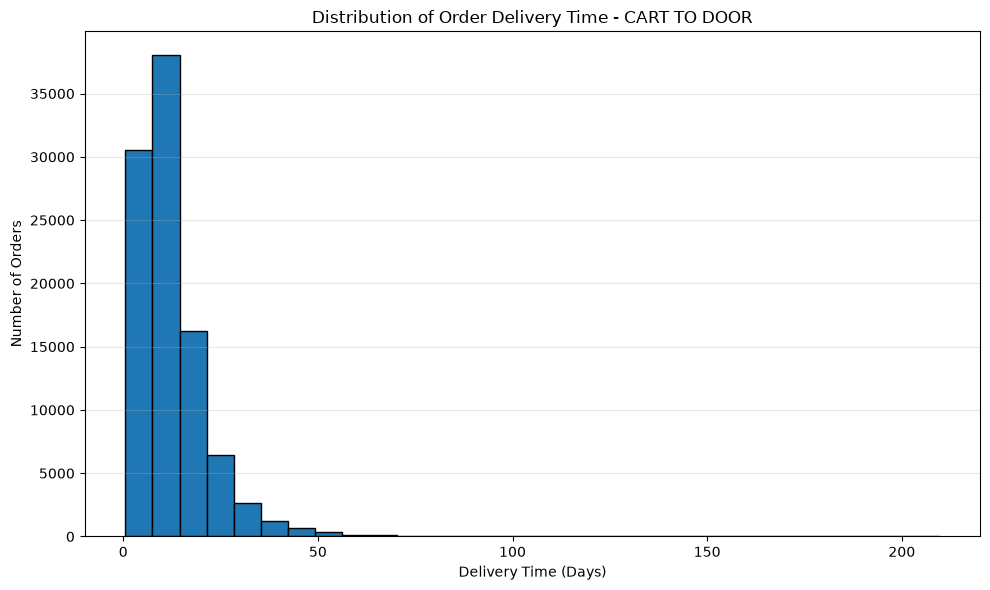

In [61]:
# Delivery Time Distribution

delivery_pd = delivery_time.select("delivery_days").toPandas()

plt.figure(figsize=(10, 6))

plt.hist(
    delivery_pd["delivery_days"],
    bins=30,
    edgecolor="black"
)

plt.title("Distribution of Order Delivery Time - CART TO DOOR")
plt.xlabel("Delivery Time (Days)")
plt.ylabel("Number of Orders")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()

In [62]:
# Late vs On-Time Delivery Analysis

from pyspark.sql.functions import when, col, count

delivery_comparison = (
    delivery_df
    .filter(
        (col("order_status") == "delivered") &
        col("delivered_date").isNotNull()
    )
    .withColumn(
        "delivery_status",
        when(
            col("delivered_date") >
            to_timestamp(
                col("order_estimated_delivery_date"),
                "M/d/yyyy H:mm"
            ),
            "Late Delivery"
        ).otherwise("On-Time or Early")
    )
)

late_analysis = (
    delivery_comparison
    .groupBy("delivery_status")
    .agg(count("*").alias("total_orders"))
)

late_analysis.show()

+----------------+------------+
| delivery_status|total_orders|
+----------------+------------+
|   Late Delivery|        7826|
|On-Time or Early|       88644|
+----------------+------------+



In [63]:
# Late Delivery Percentage

late_pd = late_analysis.toPandas()

total_deliveries = late_pd["total_orders"].sum()

late_pd["percentage"] = (
    late_pd["total_orders"] / total_deliveries
) * 100

display(late_pd.round(2))

c:\Users\HP\Desktop\Cart_to_Door\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
c:\Users\HP\Desktop\Cart_to_Door\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:374: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


,delivery_status,total_orders,percentage
0,Late Delivery,7826,8.11
1,On-Time or Early,88644,91.89


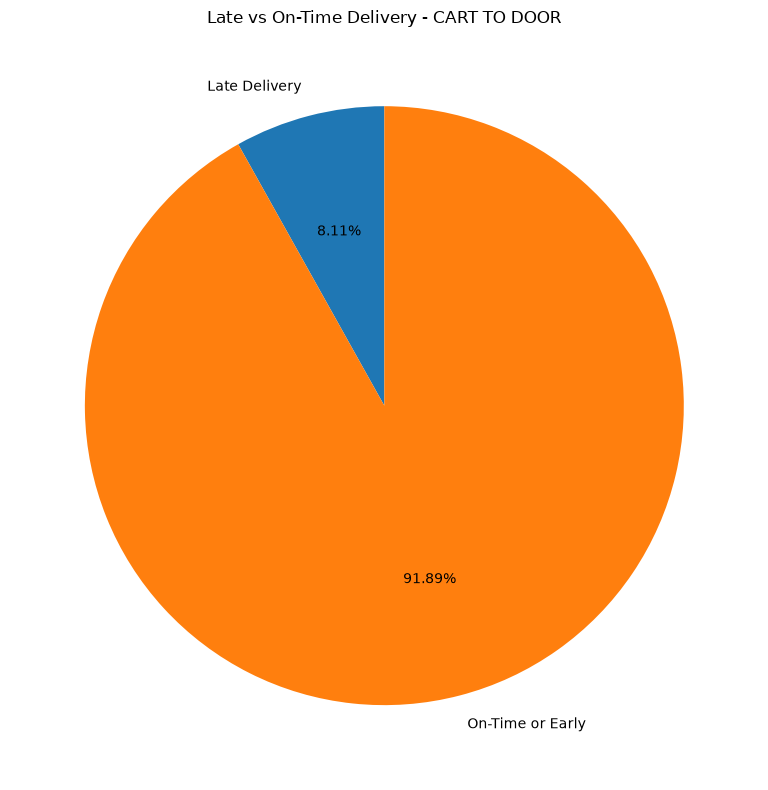

In [64]:
plt.figure(figsize=(8, 8))

plt.pie(
    late_pd["total_orders"],
    labels=late_pd["delivery_status"],
    autopct="%1.2f%%",
    startangle=90
)

plt.title("Late vs On-Time Delivery - CART TO DOOR")
plt.tight_layout()
plt.show()

In [65]:
from pyspark.sql.functions import count, sum

payment_df = datasets["payments"]

payment_analysis = (
    payment_df
    .groupBy("payment_type")
    .agg(
        count("*").alias("total_payments"),
        sum("payment_value").alias("total_payment_value")
    )
    .orderBy("total_payments", ascending=False)
)

payment_analysis.show()

+------------+--------------+--------------------+
|payment_type|total_payments| total_payment_value|
+------------+--------------+--------------------+
| credit_card|         76795|1.2542084189999327E7|
|      boleto|         19784|  2869361.2699999753|
|     voucher|          5775|   379436.8700000007|
|  debit_card|          1529|   217989.7900000001|
| not_defined|             3|                 0.0|
+------------+--------------+--------------------+



c:\Users\HP\Desktop\Cart_to_Door\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
c:\Users\HP\Desktop\Cart_to_Door\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:374: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


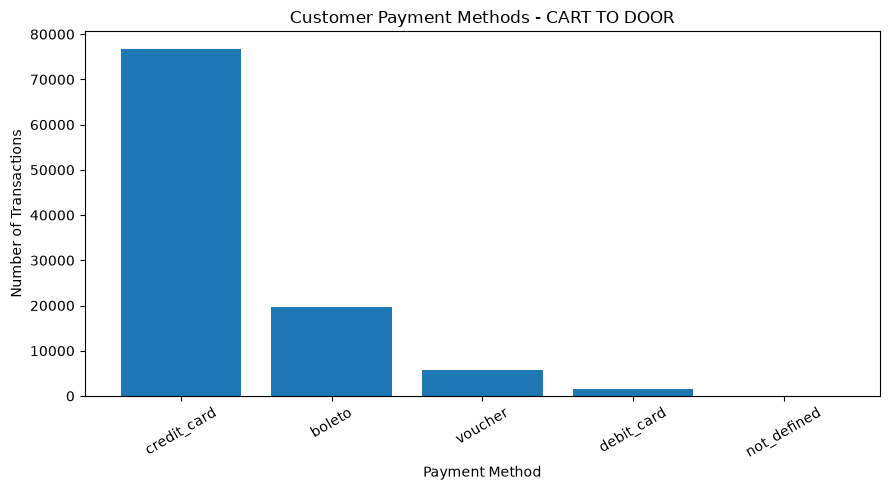

In [66]:
payment_pd = payment_analysis.toPandas()

plt.figure(figsize=(9, 5))

plt.bar(
    payment_pd["payment_type"],
    payment_pd["total_payments"]
)

plt.title("Customer Payment Methods - CART TO DOOR")
plt.xlabel("Payment Method")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [67]:
from pyspark.sql.functions import count, desc

products_df = datasets["products"]
items_df = datasets["order_items"]
category_df = datasets["category_translation"]

category_analysis = (
    items_df
    .join(products_df, "product_id", "inner")
    .join(category_df, "product_category_name", "left")
    .groupBy("product_category_name_english")
    .agg(count("order_item_id").alias("total_orders"))
    .orderBy(desc("total_orders"))
)

category_analysis.show(10, truncate=False)

+-----------------------------+------------+
|product_category_name_english|total_orders|
+-----------------------------+------------+
|bed_bath_table               |11115       |
|health_beauty                |9670        |
|sports_leisure               |8641        |
|furniture_decor              |8334        |
|computers_accessories        |7827        |
|housewares                   |6964        |
|watches_gifts                |5991        |
|telephony                    |4545        |
|garden_tools                 |4347        |
|auto                         |4235        |
+-----------------------------+------------+
only showing top 10 rows


c:\Users\HP\Desktop\Cart_to_Door\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
c:\Users\HP\Desktop\Cart_to_Door\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:374: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


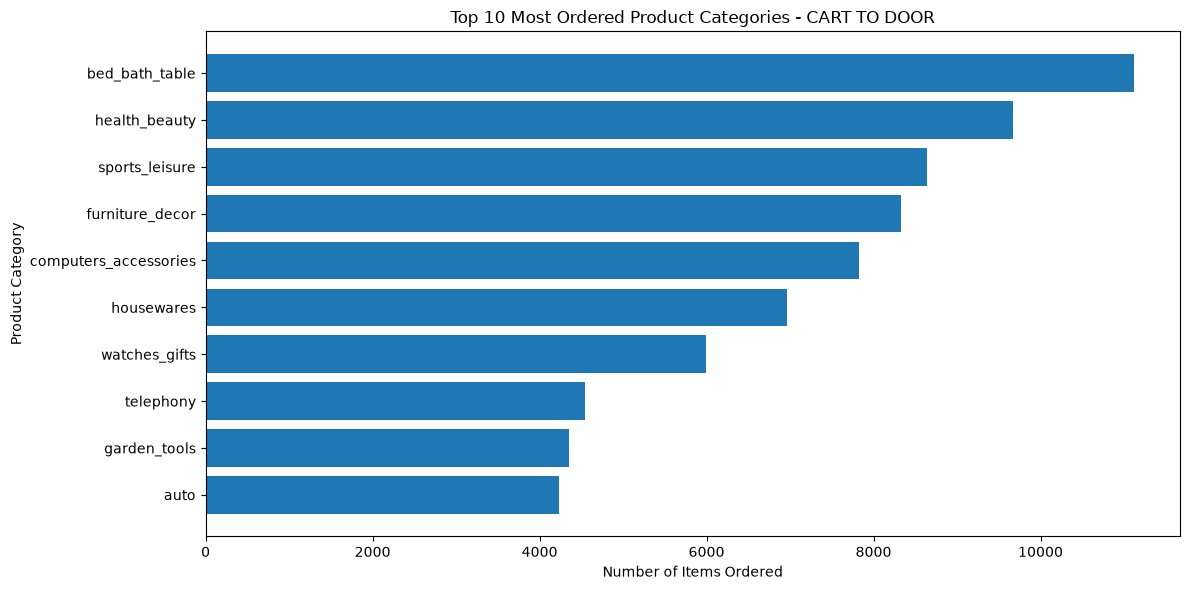

In [68]:
category_pd = category_analysis.limit(10).toPandas()

plt.figure(figsize=(12, 6))

plt.barh(
    category_pd["product_category_name_english"],
    category_pd["total_orders"]
)

plt.title("Top 10 Most Ordered Product Categories - CART TO DOOR")
plt.xlabel("Number of Items Ordered")
plt.ylabel("Product Category")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [69]:
seller_analysis = (
    items_df
    .groupBy("seller_id")
    .agg(
        count("order_item_id").alias("total_items_sold")
    )
    .orderBy("total_items_sold", ascending=False)
)

seller_analysis.show(10, truncate=False)

+--------------------------------+----------------+
|seller_id                       |total_items_sold|
+--------------------------------+----------------+
|6560211a19b47992c3666cc44a7e94c0|2033            |
|4a3ca9315b744ce9f8e9374361493884|1987            |
|1f50f920176fa81dab994f9023523100|1931            |
|cc419e0650a3c5ba77189a1882b7556a|1775            |
|da8622b14eb17ae2831f4ac5b9dab84a|1551            |
|955fee9216a65b617aa5c0531780ce60|1499            |
|1025f0e2d44d7041d6cf58b6550e0bfa|1428            |
|7c67e1448b00f6e969d365cea6b010ab|1364            |
|ea8482cd71df3c1969d7b9473ff13abc|1203            |
|7a67c85e85bb2ce8582c35f2203ad736|1171            |
+--------------------------------+----------------+
only showing top 10 rows


c:\Users\HP\Desktop\Cart_to_Door\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
c:\Users\HP\Desktop\Cart_to_Door\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:374: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


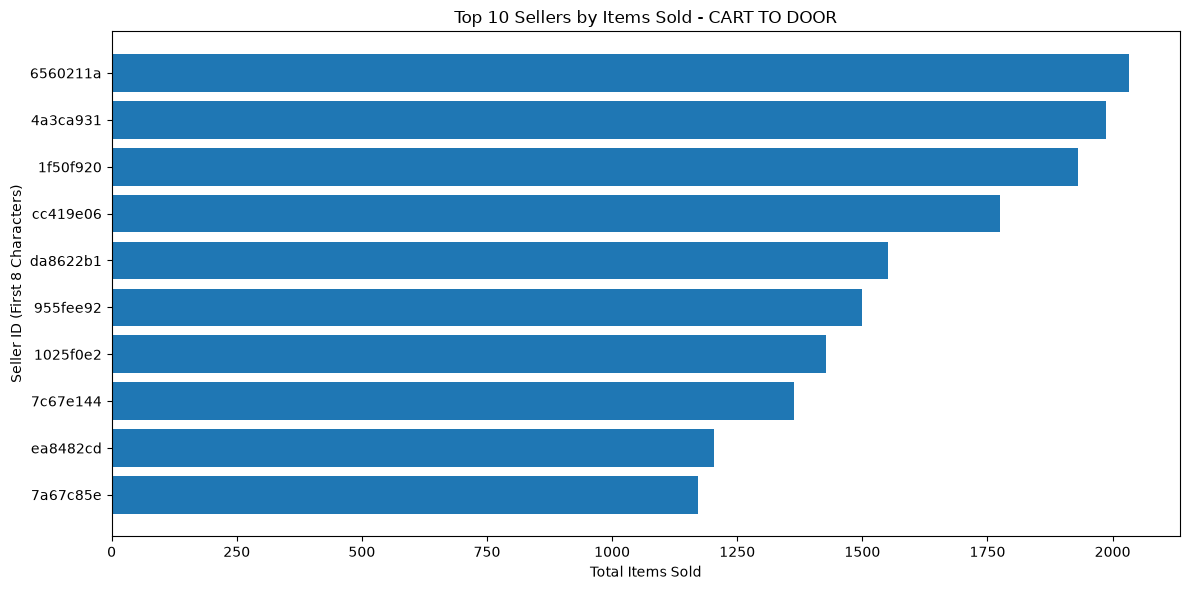

In [70]:
seller_pd = seller_analysis.limit(10).toPandas()

plt.figure(figsize=(12, 6))

plt.barh(
    seller_pd["seller_id"].str[:8],
    seller_pd["total_items_sold"]
)

plt.title("Top 10 Sellers by Items Sold - CART TO DOOR")
plt.xlabel("Total Items Sold")
plt.ylabel("Seller ID (First 8 Characters)")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [71]:
import os

RESULTS_PATH = "../data/processed/rashi_results"

os.makedirs(RESULTS_PATH, exist_ok=True)

print("Results folder created successfully!")
print(RESULTS_PATH)

Results folder created successfully!
../data/processed/rashi_results


In [72]:
# 1. Monthly Orders
monthly_orders.toPandas().to_csv(
    os.path.join(RESULTS_PATH, "monthly_orders.csv"),
    index=False
)

# 2. Top Customer Cities
top_cities = (
    datasets["customers"]
    .groupBy("customer_city")
    .agg(count("*").alias("total_customers"))
    .orderBy("total_customers", ascending=False)
    .limit(10)
)

top_cities.toPandas().to_csv(
    os.path.join(RESULTS_PATH, "top_customer_cities.csv"),
    index=False
)

# 3. Late vs On-Time Delivery
late_pd.to_csv(
    os.path.join(RESULTS_PATH, "delivery_performance.csv"),
    index=False
)

# 4. Payment Methods
payment_pd.to_csv(
    os.path.join(RESULTS_PATH, "payment_methods.csv"),
    index=False
)

# 5. Product Categories
category_analysis.toPandas().to_csv(
    os.path.join(RESULTS_PATH, "product_categories.csv"),
    index=False
)

# 6. Seller Performance
seller_analysis.toPandas().to_csv(
    os.path.join(RESULTS_PATH, "seller_performance.csv"),
    index=False
)

print("All analysis results exported successfully!")

c:\Users\HP\Desktop\Cart_to_Door\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
c:\Users\HP\Desktop\Cart_to_Door\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:374: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)
c:\Users\HP\Desktop\Cart_to_Door\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_mini

All analysis results exported successfully!


In [73]:
result_files = os.listdir(RESULTS_PATH)

print("TOTAL FILES:", len(result_files))
print("\nEXPORTED FILES:")

for file in result_files:
    print("✔", file)

TOTAL FILES: 6

EXPORTED FILES:
✔ delivery_performance.csv
✔ monthly_orders.csv
✔ payment_methods.csv
✔ product_categories.csv
✔ seller_performance.csv
✔ top_customer_cities.csv


In [74]:
summary = """
CART TO DOOR
The Hidden Story Behind Every Online Order

RASHI - PART 1: DATA UNDERSTANDING AND EXPLORATORY ANALYSIS

1. Dataset Overview
- Analysed Brazilian Olist E-commerce dataset.
- Loaded 9 CSV datasets using Apache Spark.
- Used PySpark for data processing and analysis.

2. Customer Analysis
- Total customer records: 99,441
- Unique customers: 96,096
- Customer cities: 4,119
- Sao Paulo had the highest customer count.

3. Order Analysis
- Total orders: 99,441
- Delivered orders: 96,478
- Delivered order percentage: approximately 97.01%

4. Delivery Analysis
- Average delivery time: 12.56 days
- Minimum delivery time: 0.53 days
- Maximum delivery time: 209.63 days
- Late deliveries: 7,826 (8.11%)
- On-time or early deliveries: 88,644 (91.89%)

5. Payment Analysis
- Credit card was the most popular payment method.
- Total credit card transactions: 76,795.

6. Product Category Analysis
- Bed, Bath & Table was the most ordered category.
- Total items: 11,115.

7. Seller Analysis
- The highest-selling seller sold 2,033 items.

8. Tools and Technologies
- Python
- Apache Spark
- PySpark
- Pandas
- Matplotlib
- Seaborn
- Jupyter Notebook

9. Output Files
- monthly_orders.csv
- top_customer_cities.csv
- delivery_performance.csv
- payment_methods.csv
- product_categories.csv
- seller_performance.csv
"""

summary_path = "../documentation/Rashi_Part1_Summary.txt"

with open(summary_path, "w", encoding="utf-8") as file:
    file.write(summary)

print("Rashi Part 1 Summary saved successfully!")
print(summary_path)

Rashi Part 1 Summary saved successfully!
../documentation/Rashi_Part1_Summary.txt
